# 04 — Évaluation finale, analyse des erreurs et `predict_magnitude`

Les modèles ont été choisis et entraînés au notebook 03 **sans voir le test**. Ici, on les évalue **une seule fois**
sur les 1 200 séismes de test (bruit réel jamais vu), puis sur les 4 séismes réels. **Aucun modèle n'est ré-entraîné
ni modifié** dans ce notebook.

In [ ]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore", category=UserWarning)
import pandas as _pd; warnings.filterwarnings("ignore", category=_pd.errors.PerformanceWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from src import config as C, pegs_io as io, generate as G, modeling as M, features as F
from src.predict import predict_magnitude

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 220, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
pd.set_option("display.width", 200)
MODEL_DIR = C.PROJECT_ROOT / "models"
COL = {"dummy": C.C_MUTED, "ridge": "#1baf7a", "xgboost": C.C_SIGNAL}
NAMES = {"dummy": "Dummy", "ridge": "Ridge", "xgboost": "XGBoost"}

test = pd.read_csv(C.PROCESSED_DIR / "test.csv")
real = pd.read_csv(C.PROCESSED_DIR / "real.csv")
models = {n: joblib.load(MODEL_DIR / f"{n}.joblib") for n in ["dummy", "ridge", "xgboost"]}
card = json.loads((MODEL_DIR / "model_card.json").read_text())
for n, b in models.items():
    test[f"pred_{n}"] = b["model"].predict(test[b["features"]])
test["res"] = test.pred_xgboost - test.mw          # résidu : > 0 surestimation, < 0 sous-estimation
print(f"{len(test)} séismes de test évalués")

1200 séismes de test évalués


## 1. Résultats sur le test

On compare au score de validation croisée du notebook 03 : si le test est proche, le modèle **généralise** (pas de
sur-apprentissage caché ni de fuite). L'intervalle de confiance à 95 % de la MAE est estimé par **bootstrap**
(1 000 ré-échantillonnages des séismes du test).

In [ ]:
rng = np.random.default_rng(C.RANDOM_STATE)
boot_idx = [rng.integers(0, len(test), len(test)) for _ in range(1000)]
cv_names = {"dummy": "Dummy (moyenne)", "ridge": [k for k in card["cv"] if k.startswith("Ridge")][0],
            "xgboost": "XGBoost optimisé — A+B"}
rows = []
for n in models:
    s = M.scores(test.mw, test[f"pred_{n}"])
    err = (test[f"pred_{n}"] - test.mw).abs().values
    lo, hi = np.quantile([err[i].mean() for i in boot_idx], [0.025, 0.975])
    cv = card["cv"][cv_names[n]]
    rows.append({"modèle": NAMES[n], "MAE test": s["MAE"], "IC 95 % MAE": f"[{lo:.3f} ; {hi:.3f}]",
                 "RMSE test": s["RMSE"], "R² test": s["R2"],
                 "MAE val. croisée": f"{cv['MAE val (moy)']:.3f} ± {cv['MAE val (é.-t.)']:.3f}"})
res_test = pd.DataFrame(rows).set_index("modèle")
res_test.to_csv(C.PROJECT_ROOT / "reports" / "04_resultats_test.csv")
res_test.round(3)

,MAE test,IC 95 % MAE,RMSE test,R² test,MAE val. croisée
modèle,,,,,
Dummy,0.623,[0.603 ; 0.643],0.722,-0.000,0.621 ± 0.007
Ridge,0.375,[0.360 ; 0.392],0.475,0.568,0.362 ± 0.013
XGBoost,0.295,[0.282 ; 0.308],0.380,0.723,0.281 ± 0.009


**Lecture** : XGBoost obtient sur le test une MAE de **0,295** (IC 95 % : 0,282 – 0,308), R² = 0,72.
C'est un peu moins bon qu'en validation croisée (0,281 ± 0,009), mais le décalage (+0,014) est du même ordre que la
variation d'une heure de bruit à l'autre (MAE de 0,28 à 0,32 selon l'heure de bruit du test) : le test utilise 6 heures
de bruit **jamais vues**. Le classement est identique (Dummy 0,62 > Ridge 0,38 > XGBoost 0,30) et Ridge subit le même
léger décalage. Une **fuite de données** se trahirait au contraire par un test bien plus mauvais que la validation :
ce n'est pas le cas. **Le modèle généralise.**

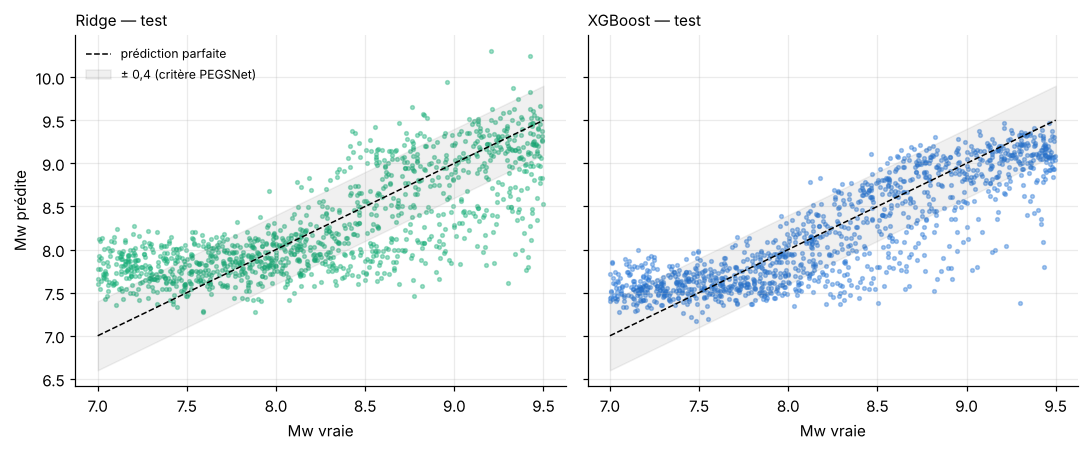

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for ax, n in zip(axes, ["ridge", "xgboost"]):
    ax.scatter(test.mw, test[f"pred_{n}"], s=6, alpha=0.4, color=COL[n])
    ax.plot([7, 9.5], [7, 9.5], "k--", lw=1, label="prédiction parfaite")
    ax.fill_between([7, 9.5], [6.6, 9.1], [7.4, 9.9], color="k", alpha=0.06, label="± 0,4 (critère PEGSNet)")
    ax.set_xlabel("Mw vraie"); ax.set_title(f"{NAMES[n]} — test", loc="left", fontsize=10)
axes[0].set_ylabel("Mw prédite"); axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(C.FIG_DIR / "04_test_pred_vs_true.png"); plt.show()

## 2. Erreurs par tranche de magnitude

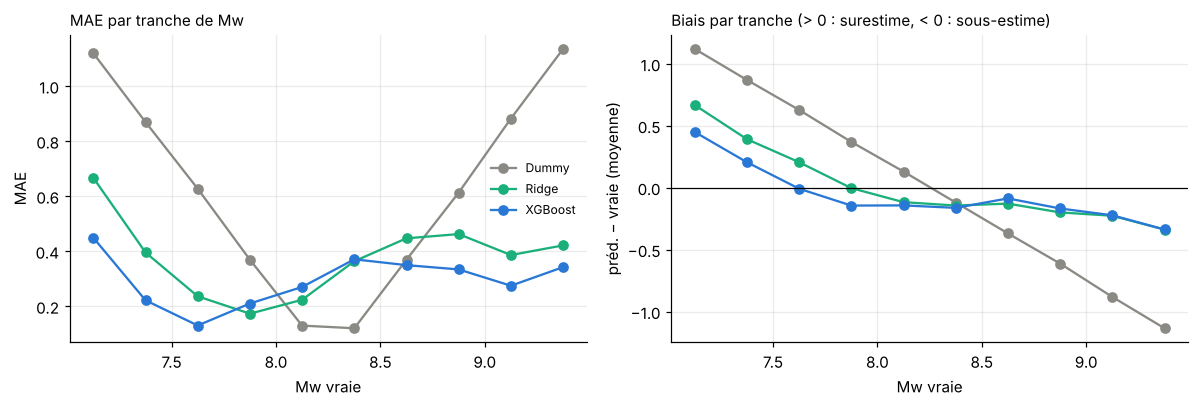

,n,MAE,biais,pct_erreur_sup_0_4
mw,,,,
"(7.0, 7.25]",120,0.449,0.449,57.500
"(7.25, 7.5]",121,0.222,0.205,8.264
"(7.5, 7.75]",115,0.130,-0.009,0.870
"(7.75, 8.0]",139,0.210,-0.145,12.950
"(8.0, 8.25]",118,0.270,-0.143,26.271
"(8.25, 8.5]",116,0.370,-0.163,35.345
"(8.5, 8.75]",125,0.349,-0.087,34.400
"(8.75, 9.0]",108,0.334,-0.168,28.704
"(9.0, 9.25]",107,0.275,-0.223,21.495


In [ ]:
bins = pd.cut(test.mw, np.arange(7, 9.51, 0.25))
mid = [iv.mid for iv in bins.cat.categories]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
for n in models:
    r = test[f"pred_{n}"] - test.mw
    a1.plot(mid, r.abs().groupby(bins, observed=False).mean().values, "o-", color=COL[n], label=NAMES[n])
    a2.plot(mid, r.groupby(bins, observed=False).mean().values, "o-", color=COL[n], label=NAMES[n])
a1.set_title("MAE par tranche de Mw", loc="left", fontsize=10); a1.set_xlabel("Mw vraie"); a1.set_ylabel("MAE")
a2.axhline(0, color="k", lw=0.8)
a2.set_title("Biais par tranche (> 0 : surestime, < 0 : sous-estime)", loc="left", fontsize=10)
a2.set_xlabel("Mw vraie"); a2.set_ylabel("préd. − vraie (moyenne)"); a1.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(C.FIG_DIR / "04_erreurs_par_mw.png"); plt.show()

per_bin = test.groupby(bins, observed=True).agg(n=("mw", "size"), MAE=("res", lambda x: x.abs().mean()),
                                                 biais=("res", "mean"),
                                                 pct_erreur_sup_0_4=("res", lambda x: 100 * (x.abs() > 0.4).mean()))
per_bin.round(3)

**Lecture** : trois zones bien distinctes :
- **Mw 7,0 – 7,5 : plancher de détection.** XGBoost surestime fortement les plus petits séismes (biais +0,45 entre 7,0 et
  7,25 ; 57 % des erreurs dépassent 0,4).
- **Mw 7,5 – 7,75 : MAE de 0,13, mais c'est un artefact.** Cette tranche contient justement la valeur que le modèle
  répond quand il ne voit rien (section 3).
- **Mw 8 – 9 : zone utile**, MAE de 0,27 à 0,37, avec un léger biais négatif.
- **Mw > 9 : sous-estimation croissante**, jusqu'à −0,34 en moyenne entre 9,25 et 9,5 (section 4).

Ridge a le même profil, en moins bon. Le Dummy n'est bon qu'au centre (autour de 8,25), par construction.

## 3. Le « plancher de bruit » : que prédit le modèle quand il n'y a rien à voir ?

Test décisif (repris de Licciardi et al., 2022) : on donne au modèle **du bruit réel seul, sans aucun PEGS**
(300 exemples tirés dans les heures de bruit du test), et on regarde ce qu'il prédit. Toute prédiction tombant dans
cette plage **ne se distingue pas d'une absence de signal**.

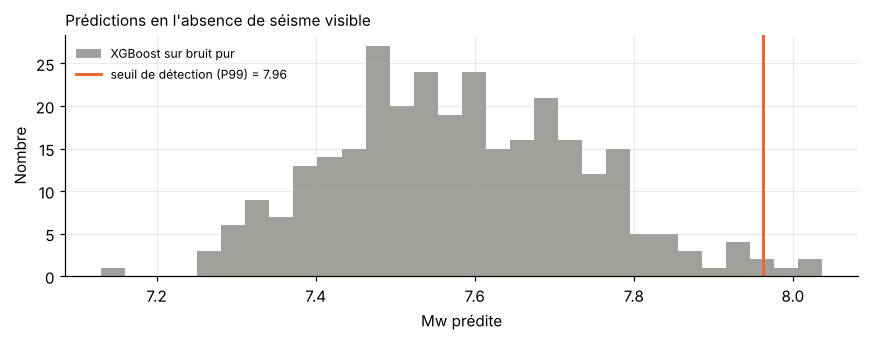

,mediane,p5,p95,p99
xgboost,7.57,7.34,7.83,7.96
ridge,7.79,7.51,8.06,8.16


In [ ]:
kernels = io.load_kernels(C.KERNEL_FILE); noise = io.load_noise(C.NOISE_FILE)
rng = np.random.default_rng(123)
t_rel = np.arange(601) - C.GRAPH_ORIGIN_IDX
noise_pred = {"xgboost": [], "ridge": []}
for _ in range(300):
    k = rng.integers(len(kernels["srclat"])); w = rng.choice(C.NOISE_TEST); s0 = rng.integers(0, 3600 - 601)
    d = noise["noise"][w, :, s0:s0 + 601].astype(float); tp = kernels["tp"][k].astype(float)
    d = np.where(t_rel[None, :] > tp[:, None], 0.0, d); d[~noise["flag"][w]] = 0.0
    for m in noise_pred:
        noise_pred[m].append(predict_magnitude(d, tp, noise["flag"][w], model=m))
baseline = {m: {"mediane": float(np.median(v)), "p5": float(np.quantile(v, 0.05)), "p95": float(np.quantile(v, 0.95)),
                "p99": float(np.quantile(v, 0.99))} for m, v in noise_pred.items()}
(MODEL_DIR / "noise_baseline.json").write_text(json.dumps(baseline, indent=2))
SEUIL = baseline["xgboost"]["p99"]

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(noise_pred["xgboost"], bins=30, color=C.C_MUTED, alpha=0.8, label="XGBoost sur bruit pur")
ax.axvline(SEUIL, color=C.C_NOISY, lw=2, label=f"seuil de détection (P99) = {SEUIL:.2f}")
ax.set_xlabel("Mw prédite"); ax.set_ylabel("Nombre"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Prédictions en l'absence de séisme visible", loc="left", fontsize=10)
fig.tight_layout(); fig.savefig(C.FIG_DIR / "04_plancher_bruit.png"); plt.show()
pd.DataFrame(baseline).T.round(2)

**Lecture** : sur du bruit pur, XGBoost répond **Mw ≈ 7,57** (90 % des cas entre 7,34 et 7,83 ; 99 % sous
**7,96**). C'est la « réponse par défaut » du modèle quand il ne voit pas de PEGS.

**Conséquence pratique** : une prédiction inférieure à ~8,0 doit être lue comme **« magnitude sous le seuil de détection
des PEGS »** et non comme une valeur fiable. Ce seuil est sauvegardé dans `models/noise_baseline.json` et utilisé par
`predict_magnitude(..., return_details=True)`. C'est cohérent avec la littérature : PEGSNet (Japon) a un seuil vers Mw 8,3,
PEGSGraph (Alaska) vers Mw 7,6 – 7,7, avec des réseaux de neurones bien plus riches que notre modèle tabulaire.

## 4. Pourquoi les très grands séismes sont-ils sous-estimés ?

Trois hypothèses avancées au notebook 03, que l'on **teste** maintenant sur les séismes de test de Mw ≥ 9.

**(a) La rupture n'est pas finie à 300 s.** Le générateur étant déterministe, on peut régénérer exactement les
séismes de test pour récupérer leur fonction source et calculer la magnitude **déjà atteinte** à 300 s.

In [ ]:
mw300 = []
for ev in G.iter_events(C.N_TEST, C.NOISE_TEST, kernels, noise, seed=C.SEED_TEST, mw_range=C.MW_RANGE):
    mw300.append((np.log10(ev["momrate"][:C.T_DECISION + 1].sum()) - 9.1) / 1.5)
test["mw300"] = mw300
test["deficit300"] = test.mw - test.mw300            # magnitude « pas encore libérée » à 300 s
big = test[test.mw >= 9].copy()
cmp = test.groupby(bins, observed=True).agg(biais=("res", "mean"), deficit_a_300s=("deficit300", "mean")).tail(4)
print(f"Séismes Mw ≥ 9 : {len(big)} | sous-estimés de plus de 0,3 : {100 * (big.res < -0.3).mean():.0f} % | "
      f"de plus de 0,5 : {100 * (big.res < -0.5).mean():.0f} %")
cmp.round(3)

Séismes Mw ≥ 9 : 238 | sous-estimés de plus de 0,3 : 41 % | de plus de 0,5 : 17 %


,biais,deficit_a_300s
mw,,
"(8.5, 8.75]",-0.087,0.001
"(8.75, 9.0]",-0.168,0.006
"(9.0, 9.25]",-0.223,0.018
"(9.25, 9.5]",-0.338,0.039


**(b) Effet de bord** : un arbre de décision prédit une moyenne d'exemples vus à l'entraînement ; il ne peut **jamais**
dépasser la plus grande valeur vue (Mw 9,5), et près de cette borne les prédictions sont « tirées » vers l'intérieur.

**(c) Détectabilité** : les grands séismes mal placés (loin du réseau) ou mal orientés produisent moins de stations
au-dessus du bruit.

(b) Mw max à l'entraînement : 9,50 | prédiction max sur le test : 9.47 | prédiction moyenne pour Mw > 9,3 : 9.04
(c) corrélation résidu / proportion de stations au-dessus du bruit (Mw ≥ 9) : 0.55
(a) corrélation résidu / déficit de magnitude à 300 s (Mw ≥ 9) : -0.48


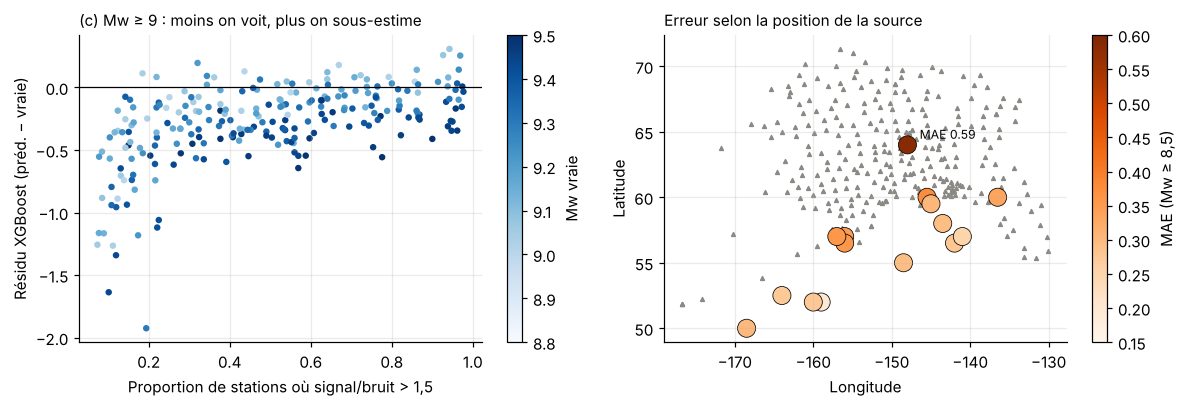

mecanisme,chevauchement,decrochement,normal
MAE par mécanisme,,,
"(7.0, 8.0]",0.257,0.249,0.250
"(8.0, 8.5]",0.325,0.256,0.396
"(8.5, 9.0]",0.405,0.329,0.293
"(9.0, 9.5]",0.310,0.275,0.348


,lat,lon,MAE,biais,n
src_id,,,,,
2,52.0,-159.0,0.196,-0.107,31
12,57.0,-141.0,0.250,-0.158,27
1,52.5,-164.0,0.274,-0.213,29
3,52.0,-160.0,0.275,-0.153,26
11,56.5,-142.0,0.278,-0.174,31
10,58.0,-143.5,0.294,-0.121,21
4,55.0,-148.5,0.294,-0.182,41
0,50.0,-168.5,0.300,-0.240,35
13,59.5,-145.0,0.304,-0.074,25


In [ ]:
print(f"(b) Mw max à l'entraînement : 9,50 | prédiction max sur le test : {test.pred_xgboost.max():.2f} | "
      f"prédiction moyenne pour Mw > 9,3 : {test[test.mw > 9.3].pred_xgboost.mean():.2f}")
r_c = np.corrcoef(big.res, big["frac_snr_gt_1.5"])[0, 1]
r_a = np.corrcoef(big.res, big.deficit300)[0, 1]
print(f"(c) corrélation résidu / proportion de stations au-dessus du bruit (Mw ≥ 9) : {r_c:.2f}")
print(f"(a) corrélation résidu / déficit de magnitude à 300 s (Mw ≥ 9) : {r_a:.2f}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
sc = a1.scatter(big["frac_snr_gt_1.5"], big.res, c=big.mw, cmap="Blues", s=18, vmin=8.8, vmax=9.5, edgecolor="none")
a1.axhline(0, color="k", lw=0.8); fig.colorbar(sc, ax=a1, label="Mw vraie")
a1.set_xlabel("Proportion de stations où signal/bruit > 1,5"); a1.set_ylabel("Résidu XGBoost (préd. − vraie)")
a1.set_title("(c) Mw ≥ 9 : moins on voit, plus on sous-estime", loc="left", fontsize=10)

pos = (test[test.mw >= 8.5].groupby("src_id")
       .agg(lat=("srclat", "first"), lon=("srclon", "first"), MAE=("res", lambda x: x.abs().mean()),
            biais=("res", "mean"), n=("res", "size")))
sta = io.load_stations(C.KERNEL_FILE)
a2.scatter(sta.lon, sta.lat, s=6, marker="^", color=C.C_MUTED, label="stations")
sc2 = a2.scatter(pos.lon, pos.lat, c=pos.MAE, s=140, cmap="Oranges", vmin=0.15, vmax=0.6, edgecolor="k", linewidth=0.5)
for _, r in pos[pos.MAE > 0.4].iterrows():   # on n'annote que la position atypique (valeurs complètes dans le tableau)
    a2.annotate(f"MAE {r.MAE:.2f}", (r.lon, r.lat), xytext=(8, 4), textcoords="offset points", fontsize=8)
fig.colorbar(sc2, ax=a2, label="MAE (Mw ≥ 8,5)")
a2.set_xlabel("Longitude"); a2.set_ylabel("Latitude"); a2.set_title("Erreur selon la position de la source", loc="left", fontsize=10)
fig.tight_layout(); fig.savefig(C.FIG_DIR / "04_sous_estimation.png"); plt.show()

mec = test.assign(ae=test.res.abs()).pivot_table(index=pd.cut(test.mw, [7, 8, 8.5, 9, 9.5]), columns="mecanisme",
                                                  values="ae", aggfunc="mean", observed=True)
display(mec.round(3).rename_axis("MAE par mécanisme"))
pos.sort_values("MAE").round(3)

**Lecture** : sur les 238 séismes de Mw ≥ 9, **41 % sont sous-estimés de plus de 0,3** et 17 % de plus de 0,5.
Les trois hypothèses, testées :
- **(a) Rupture inachevée à 300 s : effet réel mais faible.** La magnitude « pas encore libérée » à 300 s vaut au plus
  0,04 en moyenne (tranche 9,25 – 9,5), contre un biais de −0,34. Elle n'explique donc qu'une **petite partie** du
  problème. Sa corrélation avec le résidu (−0,48) s'explique surtout par le fait que déficit et biais augmentent tous
  deux avec Mw.
- **(b) Effet de bord : confirmé.** Pour Mw > 9,3, la prédiction moyenne n'est que de 9,04, et le modèle ne dépasse
  jamais 9,47. Un modèle à base d'arbres ne peut pas prédire au-delà de ce qu'il a vu, et « tasse » ses prédictions
  près de la borne 9,5.
- **(c) Détectabilité : cause principale.** Corrélation de **+0,55** entre le résidu et la proportion de stations
  au-dessus du bruit : moins le réseau « voit » le séisme, plus il est sous-estimé. La **position** de la source
  compte beaucoup : la source à 64° N, 148° O (intérieur de l'Alaska, au nord du réseau) a une MAE de **0,59** et un
  biais de −0,50, contre 0,20 à 0,38 ailleurs. Le **mécanisme** a un effet secondaire et sans tendance nette.

**Pistes d'amélioration** : élargir la plage de Mw d'entraînement au-delà de 9,5 (pour supprimer l'effet de bord),
ajouter des positions de source (la grille fournie n'en a que 15), et prendre la décision un peu plus tard pour les
séismes qui grossissent encore.

## 5. Importance des caractéristiques

Deux mesures complémentaires :
- le **gain** interne de XGBoost (combien chaque caractéristique améliore les arbres) — calculé à l'entraînement ;
- l'**importance par permutation groupée** sur le test : on mélange au hasard toutes les colonnes d'une **famille**
  (ce qui casse leur lien avec la magnitude) et on mesure de combien la MAE augmente. Plus la hausse est forte,
  plus le modèle dépend de cette famille.

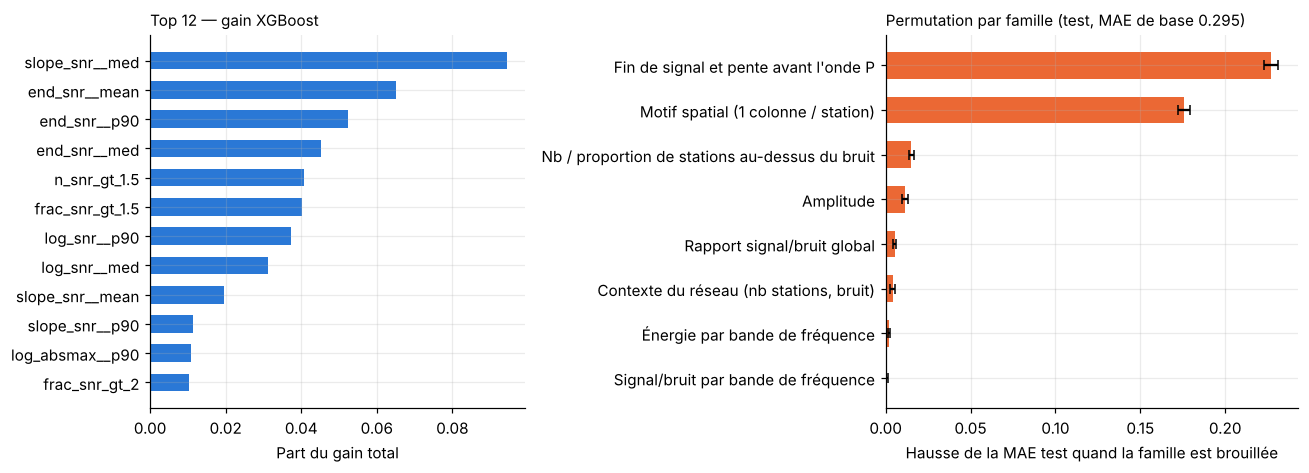

,hausse MAE,é.-t.,nb colonnes
Signal/bruit par bande de fréquence,0.001,0.001,16.0
Énergie par bande de fréquence,0.002,0.001,16.0
"Contexte du réseau (nb stations, bruit)",0.004,0.001,3.0
Rapport signal/bruit global,0.005,0.001,4.0
Amplitude,0.011,0.002,8.0
Nb / proportion de stations au-dessus du bruit,0.015,0.002,6.0
Motif spatial (1 colonne / station),0.176,0.004,261.0
Fin de signal et pente avant l'onde P,0.227,0.004,8.0


Part du gain du motif spatial : 0.421


In [ ]:
xgb = models["xgboost"]
feats = xgb["features"]
gain = pd.Series(xgb["model"].named_steps["model"].get_booster().get_score(importance_type="gain")).reindex(feats).fillna(0)
gain = (gain / gain.sum()).sort_values(ascending=False)

def family(c):
    if F.is_spatial(c): return "Motif spatial (1 colonne / station)"
    if c.startswith(("n_snr", "frac_snr")): return "Nb / proportion de stations au-dessus du bruit"
    if c.startswith("log_snr"): return "Rapport signal/bruit global"
    if c.startswith(("log_rms", "log_absmax")): return "Amplitude"
    if c.startswith(("end_snr", "slope_snr")): return "Fin de signal et pente avant l'onde P"
    if c.startswith("log_bsnr"): return "Signal/bruit par bande de fréquence"
    if c.startswith("log_e_"): return "Énergie par bande de fréquence"
    return "Contexte du réseau (nb stations, bruit)"

fam = pd.Series({c: family(c) for c in feats})
X_test = test[feats]; base_mae = np.abs(xgb["model"].predict(X_test) - test.mw).mean()
rng = np.random.default_rng(C.RANDOM_STATE)
perm = {}
for f_name, cols in fam.groupby(fam).groups.items():
    incr = []
    for _ in range(5):
        Xp = X_test.copy()
        Xp[list(cols)] = X_test[list(cols)].values[rng.permutation(len(Xp))]
        incr.append(np.abs(xgb["model"].predict(Xp) - test.mw).mean() - base_mae)
    perm[f_name] = (np.mean(incr), np.std(incr), len(cols))
perm = pd.DataFrame(perm, index=["hausse MAE", "é.-t.", "nb colonnes"]).T.sort_values("hausse MAE")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1, 1.1]})
top = gain.head(12)[::-1]
a1.barh(top.index, top.values, color=C.C_SIGNAL, height=0.6)
a1.set_xlabel("Part du gain total"); a1.set_title("Top 12 — gain XGBoost", loc="left", fontsize=10)
a2.barh(perm.index, perm["hausse MAE"], xerr=perm["é.-t."], color=C.C_NOISY, height=0.6, capsize=3)
a2.set_xlabel("Hausse de la MAE test quand la famille est brouillée")
a2.set_title(f"Permutation par famille (test, MAE de base {base_mae:.3f})", loc="left", fontsize=10)
fig.tight_layout(); fig.savefig(C.FIG_DIR / "04_importance.png"); plt.show()
display(perm.round(3))
print("Part du gain du motif spatial :", round(gain[[c for c in feats if F.is_spatial(c)]].sum(), 3))

**Lecture** : 
- La famille **« fin de signal et pente avant l'onde P »** est de loin la plus importante : la brouiller augmente la
  MAE de **+0,23**. C'est physiquement logique : le PEGS est une « rampe » qui atteint son maximum juste avant l'onde P.
- Le **motif spatial** (une colonne par station) vient ensuite : **+0,18** quand il est brouillé, et 42 % du gain
  total. Il permet au modèle de tenir compte de la **géométrie** (position, mécanisme) que l'amplitude seule ignore,
  ce qui confirme le choix A+B du notebook 03.
- Les autres familles ont une importance par permutation faible (≤ 0,015). Cela ne veut pas dire qu'elles sont
  inutiles : elles sont **redondantes** avec les deux premières (quand on en brouille une, les autres compensent).
  C'est la limite connue de l'importance par permutation avec des variables corrélées.

## 6. Traduction pour la décision : « séisme majeur (Mw ≥ 8,5) ou non ? »

Pour un centre d'alerte tsunami, la question opérationnelle est souvent binaire : faut-il déclencher l'alerte
maximale ? On transforme la prédiction en alerte avec un **seuil**, et on compte les erreurs (le choix
final du seuil dépendra des **coûts** d'une fausse alerte et d'une alerte manquée).

In [ ]:
majeur = test.mw >= 8.5
rows = []
for thr in [8.0, 8.2, 8.3, 8.5]:
    alerte = test.pred_xgboost >= thr
    tp, fn = int((majeur & alerte).sum()), int((majeur & ~alerte).sum())
    fp, tn = int((~majeur & alerte).sum()), int((~majeur & ~alerte).sum())
    rows.append({"seuil d'alerte (Mw prédite ≥)": thr, "alertes justes": tp, "séismes majeurs manqués": fn,
                 "fausses alertes": fp, "rappel (%)": 100 * tp / (tp + fn), "précision (%)": 100 * tp / (tp + fp)})
alert = pd.DataFrame(rows)
alert.to_csv(C.PROJECT_ROOT / "reports" / "04_seuils_alerte.csv", index=False)
print(f"Séismes majeurs (Mw ≥ 8,5) dans le test : {int(majeur.sum())} sur {len(test)}")
print(f"Parmi eux, estimés à ± 0,4 près : {100 * (test[majeur].res.abs() < 0.4).mean():.0f} %")
alert.round(1)

Séismes majeurs (Mw ≥ 8,5) dans le test : 471 sur 1200
Parmi eux, estimés à ± 0,4 près : 71 %


,seuil d'alerte (Mw prédite ≥),alertes justes,séismes majeurs manqués,fausses alertes,rappel (%),précision (%)
0,8.0,436,35,151,92.6,74.3
1,8.2,418,53,94,88.7,81.6
2,8.3,405,66,74,86.0,84.6
3,8.5,369,102,45,78.3,89.1


**Lecture** : avec un seuil d'alerte à **Mw prédite ≥ 8,3**, le modèle détecte **86 %** des séismes majeurs (66 manqués
sur 471) avec **85 %** d'alertes justes (74 fausses alertes). Baisser le seuil à 8,0 fait monter le rappel à 93 %, au
prix de deux fois plus de fausses alertes (151). Le seuil à retenir dépend du **coût** d'une alerte manquée par rapport
à une fausse alerte : c'est l'objet du notebook 05 (matrice de coûts, ROI).

⚠️ **Attention à la précision** : notre base contient 39 % de séismes majeurs (magnitudes uniformes), alors qu'ils
sont **beaucoup plus rares** dans la réalité (loi de Gutenberg-Richter). Le **rappel** est transposable ; la
**précision** réelle serait **plus faible** que dans ce tableau.

## 7. Les 4 séismes réels (test hors distribution)

In [ ]:
ref = io.load_stations(C.KERNEL_FILE).station.values
noms = {"201801230931A": "Kodiak 2018", "202007220612A": "Shumagin 2020",
        "202010192054A": "Sand Point 2020", "202107290615A": "Chignik 2021"}
rows = []
for p in sorted(C.REAL_DIR.glob("*.h5")):
    ev = io.load_real_event(p, ref)
    det = predict_magnitude(ev["data"], ev["tp"], ev["flag"], return_details=True)
    rows.append({"séisme": noms[p.stem[:13]], "Mw vraie": ev["mw"],
                 "Dummy": predict_magnitude(ev["data"], ev["tp"], ev["flag"], model="dummy"),
                 "Ridge": predict_magnitude(ev["data"], ev["tp"], ev["flag"], model="ridge"),
                 "XGBoost": det["mw"], "erreur XGBoost": det["mw"] - ev["mw"],
                 "au-dessus du seuil de détection ?": "oui" if det["detecte"] else "non",
                 "stations utilisées": det["n_stations_utilisees"]})
real_res = pd.DataFrame(rows)
real_res.to_csv(C.PROJECT_ROOT / "reports" / "04_seismes_reels.csv", index=False)
print(f"Seuil de détection XGBoost (P99 du bruit pur) : Mw {SEUIL:.2f}")
real_res.round(2)

Seuil de détection XGBoost (P99 du bruit pur) : Mw 7.96


,séisme,Mw vraie,Dummy,Ridge,XGBoost,erreur XGBoost,au-dessus du seuil de détection ?,stations utilisées
0,Kodiak 2018,7.92,8.25,8.07,7.81,-0.12,non,238
1,Shumagin 2020,7.80,8.25,7.75,7.82,0.02,non,244
2,Sand Point 2020,7.56,8.25,7.42,7.59,0.03,non,248
3,Chignik 2021,8.15,8.25,8.88,8.38,0.23,oui,169


**Lecture** : il faut lire ce tableau avec le seuil de détection (Mw 7,96) en tête :
- **Kodiak, Shumagin, Sand Point** : XGBoost prédit 7,59 à 7,82, **sous le seuil de détection**. Les petites erreurs
  (−0,12 ; +0,02 ; +0,03) sont une **coïncidence** : le modèle répond ~7,6–7,8 quand il ne voit rien, et ces séismes
  ont justement des magnitudes de 7,6 à 7,9. On ne peut **pas** conclure que le modèle les a « vus ».
- **Chignik 2021 (Mw 8,15)** : prédiction **8,38**, **au-dessus du seuil**. C'est le seul séisme réel réellement
  détecté, avec une erreur de +0,23 (dans la tolérance de ± 0,4), bien qu'il n'ait que 169 stations actives (réseau
  « legacy »).
- Ridge se trompe de +0,73 sur Chignik, et le Dummy répond 8,25 pour tout le monde.
- ⚠️ Nuance (découverte au notebook 05, stress tests) : quand des stations manquent, le modèle **décale ses
  prédictions vers le haut**. Chignik n'a que 169 stations actives sur 273 ; une partie de sa surestimation (+0,23)
  peut venir de cet effet. Sa détection reste plausible, mais elle est moins probante qu'il n'y paraît.

**Honnêtement** : 1 séisme réel détecté sur 4. C'est **cohérent** avec la physique (3 des 4 séismes sont sous ou au
seuil de détectabilité des PEGS en Alaska), mais **4 cas ne suffisent pas** pour valider le modèle sur données réelles.
C'est la principale limite à présenter.

## 8. La fonction `predict_magnitude(signal_pegs)`

Définie dans `src/predict.py`. Elle prend **l'enregistrement brut du réseau** (273 stations × 601 s, m/s²),
applique **exactement** le même prétraitement et les mêmes caractéristiques qu'à l'entraînement, puis le modèle final.
Si l'arrivée P et les stations actives ne sont pas fournies, elle les **déduit du signal** (zéros après l'onde P,
stations muettes).

**Test de cohérence** : on régénère les 100 premiers séismes de test à partir de leurs signaux bruts et on vérifie
que `predict_magnitude` redonne exactement les prédictions du tableau de caractéristiques.

In [ ]:
help(predict_magnitude)

Help on function predict_magnitude in module src.predict:

predict_magnitude(
    signal_pegs,
    tp=None,
    flag=None,
    station_codes=None,
    model='xgboost',
    return_details=False
)
    Estime la magnitude de moment Mw d'un séisme à partir de ses signaux PEGS.

    Paramètres
    ----------
    signal_pegs : array (n_stations, 601), m/s² — enregistrement du réseau (voir format en tête de fichier)
    tp : array (n_stations,), optionnel — arrivée de l'onde P (s après l'origine) ; déduite du signal si absente
    flag : array (n_stations,) booléen, optionnel — station active ; déduite du signal si absente
    station_codes : liste, optionnel — codes des stations si l'ordre diffère des 273 stations de référence
    model : "xgboost" (modèle final), "ridge" ou "dummy"
    return_details : si True, renvoie un dict avec la Mw, le seuil de détection et un indicateur de détection

    Retour
    ------
    float : magnitude Mw estimée, 300 s après l'origine (instant de décision du

In [ ]:
ecarts, ecarts_seul = [], []
for i, ev in enumerate(G.iter_events(C.N_TEST, C.NOISE_TEST, kernels, noise, seed=C.SEED_TEST, mw_range=C.MW_RANGE)):
    if i == 100:
        break
    ecarts.append(abs(predict_magnitude(ev["data"], ev["tp"], ev["flag"]) - test.pred_xgboost[i]))
    ecarts_seul.append(abs(predict_magnitude(ev["data"]) - test.pred_xgboost[i]))   # signal seul
print(f"Écart max (signal + tp + flag) : {max(ecarts):.2e}")
print(f"Écart max (signal SEUL, tp et flag déduits) : {max(ecarts_seul):.2e}")

# Exemple d'utilisation sur un séisme réel
ev = io.load_real_event(sorted(C.REAL_DIR.glob("*.h5"))[-1], ref)
print("\nChignik 2021, Mw vraie", round(ev["mw"], 2), "->", predict_magnitude(ev["data"], return_details=True))

Écart max (signal + tp + flag) : 0.00e+00
Écart max (signal SEUL, tp et flag déduits) : 0.00e+00

Chignik 2021, Mw vraie 8.15 -> {'mw': 8.379018783569336, 'seuil_detection': 7.961983408927917, 'detecte': True, 'n_stations_utilisees': 169}


## 9. Bilan


| Partie | Résultat |
|---|---|
| Évaluation (test, 1 200 séismes, utilisé une seule fois) | XGBoost **MAE 0,295** [0,282 ; 0,308], RMSE 0,38, R² 0,72 · Ridge 0,375 · Dummy 0,623 |
| Erreurs par magnitude | Plancher de détection : le modèle répond Mw ≈ 7,6 sur du bruit pur → prédictions < 8,0 non fiables · zone utile Mw 8 – 9 |
| Grandes magnitudes | Mw ≥ 9 : 41 % sous-estimés de plus de 0,3. Causes : détectabilité / position (principale), effet de bord à 9,5, rupture inachevée (faible) |
| Importance | Fin de signal / pente avant l'onde P ≫ motif spatial ≫ autres (redondantes) |
| Décision | Alerte « séisme majeur » au seuil 8,3 : rappel 86 %, précision 85 % (surestimée par rapport à la réalité) |
| Séismes réels | 1 sur 4 détecté (Chignik 2021 : 8,38 pour 8,15) ; les 3 autres sont sous le seuil de détection |
| `predict_magnitude` | Signal brut → Mw ; identique au pipeline (écart 0) ; signale si la prédiction est sous le seuil de détection |